# Pricing a Basket Option using Backward Stochastic Differential Equation (BSDE) Method

# Setup:
Consider a basket option written on $d = 5$ assets. Under the risk-neutral measure, the asset prices satisfy

$$
dS^{(i)}_t = r S^{(i)}_t \, dt + \sigma_i S^{(i)}_t \, dW^{(i)}_t, \qquad i = 1, \dots, d.
$$

Assume the Brownian motions are independent. Take $d = 5$, $S^{(i)}_0 = 100$, $r = 0.03$, $\sigma_i = 0.20$, $T = 1$.

The basket is

$$
B_T = \frac{1}{d} \sum_{i=1}^{d} S^{(i)}_T .
$$

The terminal payoff is

$$
g(S_T) = \max(B_T - K, 0), \qquad K = 100.
$$

The price function $V(t, S)$ satisfies the PDE

$$
V_t + \sum_{i=1}^{d} r S_i V_{S_i} + \frac{1}{2} \sum_{i=1}^{d} \sigma_i^2 S_i^2 V_{S_i S_i} - rV = 0,
$$

with terminal condition $V(T, S) = g(S)$. The associated BSDE may be written as

$$
dY_t = r Y_t \, dt + Z_t^{\top} \, dW_t, \qquad Y_T = g(S_T).
$$

Step 1 - We simulate 100,000 terminal values of $S_T$ directly using $S_T ^{(i)} =S_0 ^{(i)} \exp((r - \frac12 \sigma_i ^2)T + \sigma_i \sqrt{T} Z_i) $ , $Z_i$ is standard normal. We estimate the Monte Carlo benchmark price by $V_{MC}(0, S_0) = e ^{-rT} E[g(S_T)]$. Then we have the estimated Monte Carlo price and the Monte Carlo standard error. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F


# Parameters

d = 5
S0 = np.full(d, 100.0)
r = 0.03
sigma = np.full(d, 0.20)
T = 1
K = 100
M = 100000

rng = np.random.default_rng(2026)

Z = rng.standard_normal((M, d)) # generates Z
S_T = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z) # simulates S_T

B_T = S_T.mean(axis=1)
payoff = np.maximum(B_T - K, 0.0) #basket payoff

disc_payoff = np.exp(-r * T) * payoff # discounted price of basket option
V_MC = disc_payoff.mean()
std_err = disc_payoff.std(ddof=1) / np.sqrt(M)

print(f"The Monte Carlo price V_MC(0, S0) is {V_MC:.4f}")
print(f"Standard error:                {std_err:.4f}")

The Monte Carlo price V_MC(0, S0) is 5.2125
Standard error:                0.0206


Step 2 - Implement Deep BSDE Solver, using $N = 20$ and $\Delta t = \frac{T}{N}$. We simulate the forward process by $S_{k+1}^{(i)} = S_k ^{(i)} + rS_k ^{(i)}\Delta t + \sigma_i S_k^{(i)} \Delta W_k ^{(i)}$

In [2]:
N = 20
dt = T/N

S0 = torch.full((d,), 100.0)   
sigma = torch.full((d,), 0.20) # reformatted these as torch tensors so they work with the neural network

def simulate_forward(M):
    dW = torch.randn(M, N, d) * np.sqrt(dt) # draws a standard normal for each path, time step, and asset (d)
    S = torch.empty(M, N + 1, d)
    S[:, 0, :] = S0
    for k in range(N):
        Sk = S[:, k, :]
        S[:, k + 1, :] = Sk + r * Sk * dt + sigma * Sk * dW[:, k, :]
    return S, dW


def payoff(S_T):
    return torch.clamp(S_T.mean(dim=1) - K, min=0.0) #payoff in torch so it can be used with the NN later

Step 3 - Treating $Y_0$ as a trainable scalar parameter, we approximate $Z_k$ by a neural network: $Z_k \approx Z_{\theta}(t_k, S_k)$ where the output is a d-dimensional vector. Using a feedforward neural network with: \
• input dimension d + 1, corresponding to ($t_k, S_k$); \
• two hidden layers; \
• 64 neurons in each hidden layer; \
• the tanh activation function; \
• output dimension d.

In [3]:
class BasketNN(nn.Module):

    def __init__(self, input_dim=d + 1, hidden_dim=64, output_dim=d):
        super(BasketNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)   # d+1 dimensional input to first hidden layer
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)  # first hidden layer to second hidden layer
        self.fc3 = nn.Linear(hidden_dim, output_dim)  # second hidden layer to d-dimensional output

    def forward(self, t, S):
        x = torch.cat([t, S / 100.0], dim=1)          # normalized input (t_k, S_k / 100)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x

# Trainable Y_0
Y0 = nn.Parameter(torch.tensor(0.0))

Z_nn = BasketNN(input_dim=d + 1, hidden_dim=64, output_dim=d) # Z neural network

Step 4 -  Propagate $Y_k$ forward according to $Y_{k+1} = Y_k + rY_k \Delta t + Z_{\theta}(t_k, S_k)^T \Delta W_k$. Train the model by minimizing the loss function  $L(\theta, Y_0)=E[(Y_N - g(S_N))^2]$. We are using a batch size of 2,048 and 2,000 iterations with the Adam optimizer to train the network. We report the learned value of $Y_0$, the Monte Carlo benchmark price, the absolute difference between the two, and the final terminal loss. We see the deep learning method computes approximately the same value as the Monte Carlo benchmark.

In [4]:
batch_size = 2048
n_iterations = 2000 # this is enough for Y_0 to converge

# Adam optimizer for Y0 and the network weights theta
optimizer = torch.optim.Adam([Y0] + list(Z_nn.parameters()),lr=1e-2) #changed learning rate to 0.01 instead of 0.001


def propagate_Y(Y0, Z_nn, dW, S):
    # Y_{k+1} = Y_k + r Y_k dt + Z_theta(t_k, S_k)^T dW_k (formula to propagate Y)
    M = S.shape[0]
    Y = Y0 * torch.ones(M)
    for k in range(N):
        t = torch.full((M, 1), k * dt)
        Z = Z_nn(t, S[:, k, :])                            # shape (M, d)
        Y = Y + r * Y * dt + torch.sum(Z * dW[:, k, :], dim=1)
    return Y

loss_history = []
Y0_history = []

for it in range(n_iterations):
    # New batch of simulated paths each iteration (batch size = 2,048)
    S, dW = simulate_forward(batch_size)

    # propagate Y_k from Y0 to Y_N
    Y_N = propagate_Y(Y0, Z_nn, dW, S)

    # Terminal loss
    g_N = payoff(S[:, -1, :])
    loss = torch.mean((Y_N - g_N) ** 2)                    # loss function

    # Gradient step
    optimizer.zero_grad()   # clear gradients from the previous iteration
    loss.backward()         # gradients wrt Y0 and theta
    optimizer.step()        # updates Y0 and theta

    loss_history.append(loss.item())
    Y0_history.append(Y0.item())

    if it % 100 == 0 or it == n_iterations - 1:
        print(f"iter {it:5d} | loss {loss.item():.6f} | Y0 {Y0.item():.5f}")
        
with torch.no_grad():                        # evaluation only, no training
    S_eval, dW_eval = simulate_forward(100_000)
    Y_N_eval = propagate_Y(Y0, Z_nn, dW_eval, S_eval)
    final_loss = torch.mean((Y_N_eval - payoff(S_eval[:, -1, :])) ** 2).item()

V_MC = 5.1806   # Monte Carlo benchmark from Step 1
print(f"\nLearned Y0:            {Y0.item():.6f}")
print(f"Monte Carlo benchmark: {V_MC:.6f}")
print(f"Absolute difference:   {abs(Y0.item() - V_MC):.6f}")
print(f"Final terminal loss:   {final_loss:.6f}")

iter     0 | loss 76.352814 | Y0 0.01000
iter   100 | loss 22.678343 | Y0 0.97461
iter   200 | loss 12.997908 | Y0 1.83824
iter   300 | loss 8.458781 | Y0 2.59223
iter   400 | loss 5.420784 | Y0 3.23497
iter   500 | loss 3.174757 | Y0 3.76513
iter   600 | loss 1.853441 | Y0 4.18839
iter   700 | loss 1.212336 | Y0 4.51246
iter   800 | loss 0.936973 | Y0 4.75175
iter   900 | loss 0.669176 | Y0 4.92129
iter  1000 | loss 0.576576 | Y0 5.03424
iter  1100 | loss 0.661552 | Y0 5.10811
iter  1200 | loss 0.534544 | Y0 5.15322
iter  1300 | loss 0.538468 | Y0 5.18041
iter  1400 | loss 0.504787 | Y0 5.19548
iter  1500 | loss 0.469316 | Y0 5.20304
iter  1600 | loss 0.568649 | Y0 5.20634
iter  1700 | loss 0.512088 | Y0 5.20726
iter  1800 | loss 0.493006 | Y0 5.20858
iter  1900 | loss 0.514335 | Y0 5.20995
iter  1999 | loss 0.467304 | Y0 5.20964

Learned Y0:            5.209639
Monte Carlo benchmark: 5.180600
Absolute difference:   0.029039
Final terminal loss:   0.488140


Step 5 - Plot the training loss against the iteration number to show how the neural network converges. We also show this using a log-scale so small differences in loss are visible.

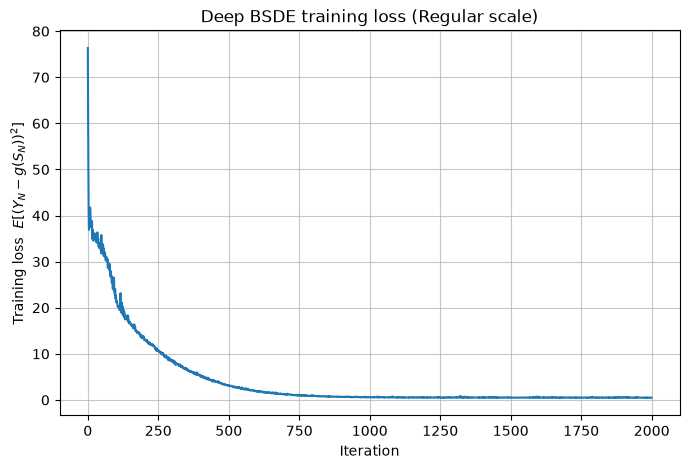

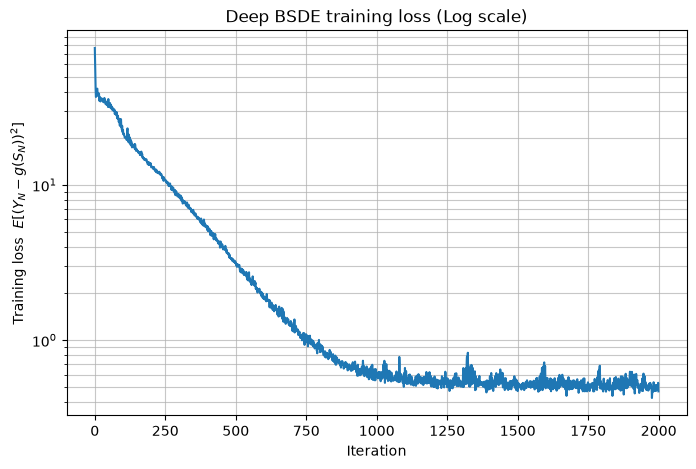

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(range(len(loss_history)), loss_history) 
plt.xlabel("Iteration")
plt.ylabel("Training loss  $E[(Y_N - g(S_N))^2]$")
plt.title("Deep BSDE training loss (Regular scale)")
plt.grid(True, which="both", alpha=0.7)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(range(len(loss_history)), loss_history)
plt.yscale("log")  
plt.xlabel("Iteration")
plt.ylabel("Training loss  $E[(Y_N - g(S_N))^2]$")
plt.title("Deep BSDE training loss (Log scale)")
plt.grid(True, which="both", alpha=0.7)
plt.show()